
# Week 3: Inference Request Trace

## Objective
Trace the complete inference process for an Indian traffic image,
from image input to final object detection response.

## Pipeline
1. Image acquisition
2. Input validation
3. Preprocessing
4. Model inference
5. Postprocessing
6. Result visualization
7. Inference response inspection

## Model
UVH-26 YOLOv11-S pretrained detector.

## Expected output
- Original input image
- Detected vehicle bounding boxes
- Predicted vehicle classes
- Confidence scores
- Inference time


In [ ]:

!pip install -q ultralytics huggingface_hub

In [ ]:

import torch
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")


Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:

from huggingface_hub import hf_hub_download

model_path = hf_hub_download(
    repo_id="iisc-aim/UVH-26",
    filename="weights/YOLOv11-S/UVH-26-MV-YOLOv11-S.pt",
    revision="v1.0"
)

print("Model downloaded successfully.")
print("Model path:", model_path)


weights/YOLOv11-S/UVH-26-MV-YOLOv11-S.pt: reconstructing file:   0%|          |  0.00B / 57.1MB            

weights/YOLOv11-S/UVH-26-MV-YOLOv11-S.pt: downloading bytes:           |  0.00B            

Model downloaded successfully.
Model path: /root/.cache/huggingface/hub/models--iisc-aim--UVH-26/snapshots/50cab97469c74773624426ec6c61fce4196dbbeb/weights/YOLOv11-S/UVH-26-MV-YOLOv11-S.pt


In [ ]:

from ultralytics import YOLO

model = YOLO(model_path)

print("Model loaded successfully.")
print("Model task:", model.task)
print("Model classes:")
print(model.names)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model loaded successfully.
Model task: detect
Model classes:
{0: 'Hatchback', 1: 'Sedan', 2: 'SUV', 3: 'MUV', 4: 'Bus', 5: 'Truck', 6: 'Three-wheeler', 7: 'Two-wheeler', 8: 'LCV', 9: 'Mini-bus', 10: 'tempo-traveller', 11: 'bicycle', 12: 'Van', 13: 'Others'}


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving traffic1.jpg to traffic1.jpg


Image name: traffic1.jpg
Image dimensions: (768, 1024, 3)
Image size: 1024 x 768


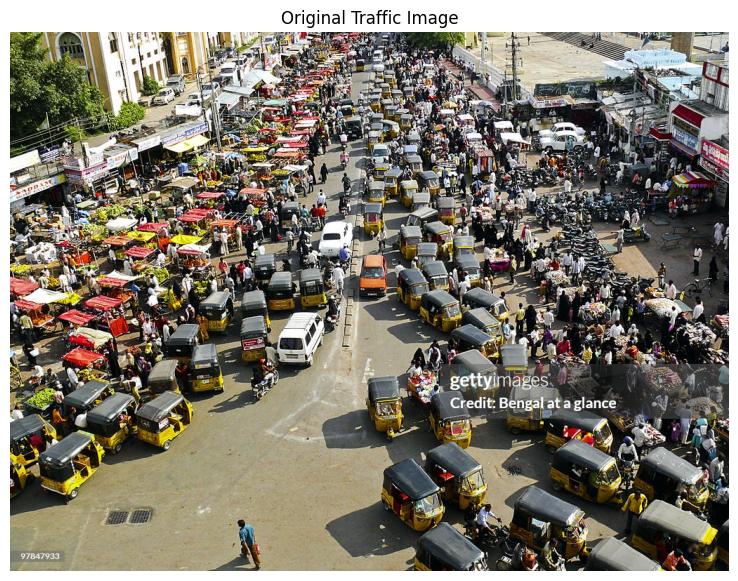

In [ ]:

import cv2
import matplotlib.pyplot as plt

image_name = next(iter(uploaded.keys()))

image = cv2.imread(image_name)

if image is None:
    raise ValueError("Image could not be loaded.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image name:", image_name)
print("Image dimensions:", image.shape)
print("Image size:", image.shape[1], "x", image.shape[0])

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Original Traffic Image")
plt.show()


In [ ]:

import time

device = 0 if torch.cuda.is_available() else "cpu"

print("Inference Request")
print("-" * 40)
print("Input:", image_name)
print("Image shape:", image.shape)
print("Device:", device)
print("Model: UVH-26 YOLOv11-S")
print("Input resolution: 640")
print("Confidence threshold: 0.25")


Inference Request
----------------------------------------
Input: traffic1.jpg
Image shape: (768, 1024, 3)
Device: 0
Model: UVH-26 YOLOv11-S
Input resolution: 640
Confidence threshold: 0.25


In [ ]:

start_time = time.perf_counter()

results = model.predict(
    source=image_name,
    imgsz=640,
    conf=0.25,
    device=device,
    verbose=False
)

end_time = time.perf_counter()

inference_time = end_time - start_time

result = results[0]

print("Inference completed.")
print(f"Execution time: {inference_time:.4f} seconds")
print(f"Execution time: {inference_time * 1000:.2f} ms")


Inference completed.
Execution time: 9.1315 seconds
Execution time: 9131.51 ms


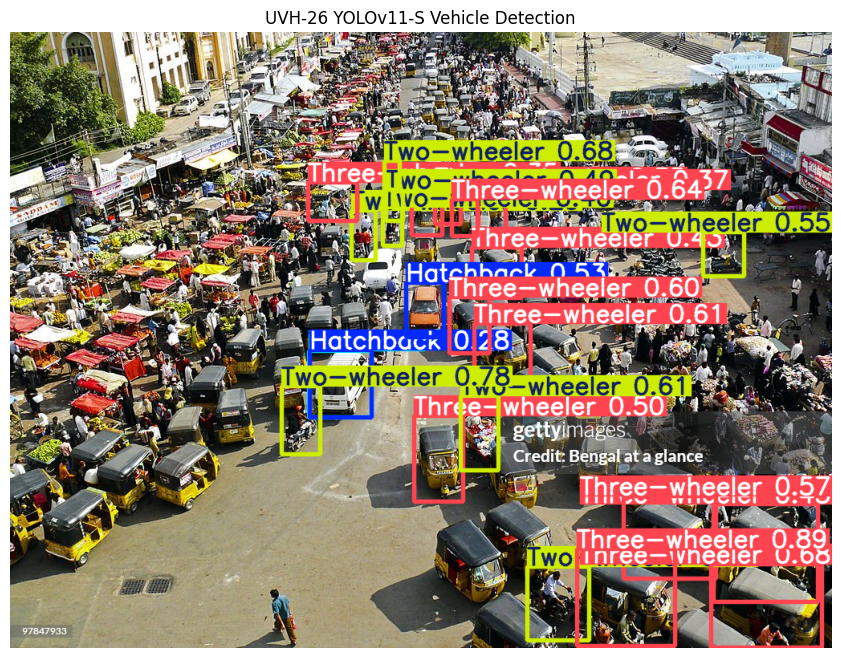

In [ ]:

annotated_image = result.plot()

annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(14, 8))
plt.imshow(annotated_image)
plt.axis("off")
plt.title("UVH-26 YOLOv11-S Vehicle Detection")
plt.show()


In [ ]:

import pandas as pd

detections = []

boxes = result.boxes

if boxes is not None:
    for i in range(len(boxes)):
        xyxy = boxes.xyxy[i].cpu().numpy()
        class_id = int(boxes.cls[i].item())
        confidence = float(boxes.conf[i].item())

        detections.append({
            "Class ID": class_id,
            "Vehicle": model.names[class_id],
            "Confidence": round(confidence, 4),
            "X1": round(float(xyxy[0]), 2),
            "Y1": round(float(xyxy[1]), 2),
            "X2": round(float(xyxy[2]), 2),
            "Y2": round(float(xyxy[3]), 2)
        })

detection_df = pd.DataFrame(detections)

detection_df


,Class ID,Vehicle,Confidence,X1,Y1,X2,Y2
0,6,Three-wheeler,0.8914,706.82,644.08,828.18,765.15
1,7,Two-wheeler,0.7765,338.23,441.02,386.53,526.99
2,6,Three-wheeler,0.6813,873.61,663.46,1011.64,767.41
3,7,Two-wheeler,0.6807,466.76,160.11,485.09,196.36
4,6,Three-wheeler,0.6424,550.45,208.13,582.92,254.66
5,7,Two-wheeler,0.6114,561.24,453.82,608.81,546.23
6,6,Three-wheeler,0.6113,578.85,363.46,648.07,431.58
7,7,Two-wheeler,0.6053,644.27,666.42,721.31,758.54
8,6,Three-wheeler,0.6023,547.29,330.64,597.66,400.23
9,6,Three-wheeler,0.5724,764.18,578.81,879.02,681.33


In [ ]:

total_detections = len(detection_df)

if total_detections > 0:
    class_counts = detection_df["Vehicle"].value_counts()

    print("Detection Summary")
    print("=" * 35)
    print("Total detected objects:", total_detections)
    print("\nDetected classes:")
    print(class_counts)

else:
    print("No vehicles detected.")


Detection Summary
Total detected objects: 24

Detected classes:
Vehicle
Three-wheeler    13
Two-wheeler       8
Hatchback         2
Van               1
Name: count, dtype: int64


In [ ]:

request_trace = pd.DataFrame([
    {
        "Stage": "1. Input",
        "Operation": "Traffic image received",
        "Status": "Completed"
    },
    {
        "Stage": "2. Validation",
        "Operation": "Image read and dimensions checked",
        "Status": "Completed"
    },
    {
        "Stage": "3. Preprocessing",
        "Operation": "Image prepared for model",
        "Status": "Handled by inference pipeline"
    },
    {
        "Stage": "4. Model Execution",
        "Operation": "YOLOv11-S prediction",
        "Status": "Completed"
    },
    {
        "Stage": "5. Postprocessing",
        "Operation": "Detection results extracted",
        "Status": "Completed"
    },
    {
        "Stage": "6. Response",
        "Operation": "Bounding boxes and classes returned",
        "Status": "Completed"
    }
])

request_trace


,Stage,Operation,Status
0,1. Input,Traffic image received,Completed
1,2. Validation,Image read and dimensions checked,Completed
2,3. Preprocessing,Image prepared for model,Handled by inference pipeline
3,4. Model Execution,YOLOv11-S prediction,Completed
4,5. Postprocessing,Detection results extracted,Completed
5,6. Response,Bounding boxes and classes returned,Completed


In [ ]:

print("=" * 50)
print("VISIONPORT INFERENCE REPORT")
print("=" * 50)

print("Model        : UVH-26 YOLOv11-S")
print("Input        :", image_name)
print("Image shape  :", image.shape)
print("Device       :", device)
print("Detections   :", total_detections)
print("Inference time:", f"{inference_time * 1000:.2f} ms")

if total_detections > 0:
    print("\nDetected vehicles:")
    print(detection_df["Vehicle"].value_counts().to_string()

)
else:
    print("\nNo objects detected.")

print("\nInference request completed successfully.")


VISIONPORT INFERENCE REPORT
Model        : UVH-26 YOLOv11-S
Input        : traffic1.jpg
Image shape  : (768, 1024, 3)
Device       : 0
Detections   : 24
Inference time: 9131.51 ms

Detected vehicles:
Vehicle
Three-wheeler    13
Two-wheeler       8
Hatchback         2
Van               1

Inference request completed successfully.



# Week 3 Conclusion

Successfully executed the inference request lifecycle for an Indian
traffic image using the pretrained UVH-26 YOLOv11-S model.

## Completed
- Input image acquisition
- Input validation
- GPU availability verification
- Model checkpoint loading
- Image inference
- Bounding box visualization
- Vehicle class extraction
- Confidence score extraction
- Structured detection output
- Request lifecycle tracing
- Inference time measurement

## Request Lifecycle

Input Image
    ↓
Validation
    ↓
Preprocessing
    ↓
Model Execution
    ↓
Postprocessing
    ↓
Detection Response

## Key Learning

An inference system is not merely a trained model.
It includes input handling, preprocessing, execution,
postprocessing and response delivery.
Each stage contributes to the overall system behavior
and latency.


In [ ]:
print("=" * 50)
print("VISIONPORT INFERENCE REPORT")
print("=" * 50)

print("Model         : UVH-26 YOLOv11-S")
print("Input         :", image_name)
print("Image shape   :", image.shape)
print("Device        :", device)
print("Detections    :", total_detections)
print("Inference time:", f"{inference_time * 1000:.2f} ms")

if total_detections > 0:
    print("\nDetected vehicles:")
    print(detection_df["Vehicle"].value_counts().to_string())
else:
    print("\nNo objects detected.")

print("\nInference request completed successfully.")

VISIONPORT INFERENCE REPORT
Model         : UVH-26 YOLOv11-S
Input         : traffic1.jpg
Image shape   : (768, 1024, 3)
Device        : 0
Detections    : 24
Inference time: 9131.51 ms

Detected vehicles:
Vehicle
Three-wheeler    13
Two-wheeler       8
Hatchback         2
Van               1

Inference request completed successfully.
